In [2]:
import pandas as pd
import matplotlib.pyplot as plt # viz
import seaborn as sns # better viz
import numpy as np # numerical python

%matplotlib inline
pd.set_option('display.max_columns', None)

In [3]:
# Load and create a copy of the data
data = pd.read_csv("amz_uk_price_prediction_dataset.csv")
df = data.copy()

In [ ]:
# Confirm all looks good
df.head()

# Basics of the dataset were already explored in the univariate analysis section

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


## 1. Analysing Best-Seller Trends Across Product Categories

**Objective: Understand the relationship between product categories and their best-seller status.**

### 1.1 Crosstab analysis

In [12]:
bestseller_ct = pd.crosstab(df["category"], df["isBestSeller"])
display(bestseller_ct)

isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3
...,...,...
Wind Instruments,243,7
Window Treatments,234,5
Women,17559,213


In [13]:
# add a column to the crosstab with the proportion of bestsellers in a category
bestseller_ct["proportion"] = bestseller_ct[True] / (bestseller_ct[True] + bestseller_ct[False])
display(bestseller_ct)

isBestSeller,False,True,proportion
category,,,
3D Printers,247,1,0.004032
3D Printing & Scanning,4065,2,0.000492
Abrasive & Finishing Products,245,5,0.020000
Action Cameras,1696,1,0.000589
Adapters,251,3,0.011811
...,...,...,...
Wind Instruments,243,7,0.028000
Window Treatments,234,5,0.020921
Women,17559,213,0.011985


In [17]:
bestseller_ct.sort_values(by="proportion", ascending=False, inplace=True)
display(bestseller_ct)
display(bestseller_ct.head(15))

isBestSeller,False,True,proportion
category,,,
Grocery,9008,556,0.058135
Smart Home Security & Lighting,98,6,0.057692
Health & Personal Care,9017,552,0.057686
Mobile Phone Accessories,248,11,0.042471
Power & Hand Tools,8353,306,0.035339
...,...,...,...
Motorbike Chassis,107,0,0.000000
Motorbike Seat Covers,249,0,0.000000
Digital Frames,774,0,0.000000


isBestSeller,False,True,proportion
category,,,
Grocery,9008,556,0.058135
Smart Home Security & Lighting,98,6,0.057692
Health & Personal Care,9017,552,0.057686
Mobile Phone Accessories,248,11,0.042471
Power & Hand Tools,8353,306,0.035339
"Billiard, Snooker & Pool",241,8,0.032129
Pet Supplies,9152,285,0.030200
Home Brewing & Wine Making,239,7,0.028455
Wind Instruments,243,7,0.028000


In [16]:
no_best_sellers = (bestseller_ct['proportion'] == 0).sum()
int(no_best_sellers)

36

Sorting the crosstab between product categories and bestseller status by the proportion of bestsellers in any given product category shows that no category has more than 6% of its products tagged as bestsellers, with the Grocery category having the highest percentage with 5.81%. The percentage also drops quite rapidly, with only seven categories having 3% or more of its products marked as best sellers. Notably there are also many smaller product categories featured in the top 15 of best sellers by proportion: while five of the categories have thousands of items each, the other ten have less than 250 items each.

Checking for 0 values in the proportion calculation column, we can also see that 36 columns have no bestsellers.

### 1.2 Statistical Tests

In [20]:
bestseller_ct.drop(columns=["proportion"], inplace=True)

In [23]:
from scipy.stats import chi2_contingency

_, chi2_value, _, _ = chi2_contingency(bestseller_ct)

float(chi2_value)

0.0

In [22]:
float(chi2_value) < 0.05

True

The p-value of 0.0 yielded from the Chi-square test suggest an extremely significant association between the category and the best-seller distribution. The perfect 0 is likely yielded by a p-value smaller than the precision available to the computation.

In [24]:
from scipy.stats.contingency import association

association(bestseller_ct, method="cramer")

0.1222829439760564

The Cramer's V computation result of 0.122 suggest a weak association between the product category and best seller status.

### 1.3 Visualisation

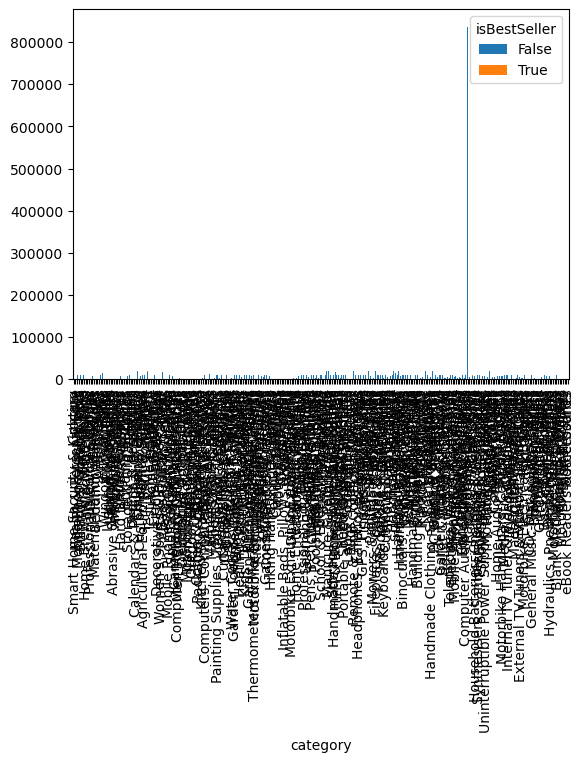

In [25]:
bestseller_ct.plot(kind="bar", stacked=True)
plt.show()

Visualising the complete crosstab in a stacked bar chart does not yield readable or interpretable results as the number of categories is high and the number of products per category is significantly skewed to one category and the proportions of bestsellers per category are quite small.

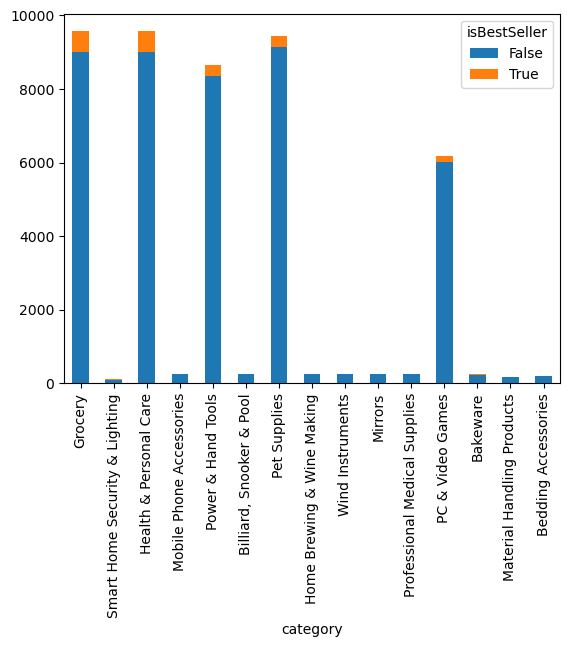

In [28]:
bestseller_ct.head(15).plot(kind="bar", stacked=True)
plt.show()

Visualising just the top 15 categories by proportion of best sellers is more reasonable, but further illustrates the problem from above: even in the better spaced plot, many categories have so few products compared to others that their count of bestsellers is negligible enough to be invisible in the plot. 

## 2. Exploring Product Prices and Ratings Across Categories and Brands

**Objective: Investigate how different product categories influence product prices.**

### 2.0 Remove product price outliers

In [31]:
# get Q1 and Q3
Q1 = df["price"].quantile(0.25)
Q3 = df["price"].quantile(0.75)

# calculate interquantile range
IQR = Q3 - Q1

# define outlier boundaries
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# filter the dataframe based on price outliers
filtered_data = df[(df["price"] >= lower_bound) & (df["price"] <= upper_bound)]

display(filtered_data)

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers
...,...,...,...,...,...,...,...,...,...
2443646,2828589,B0CHSD7P2Q,"Motorbike Armour, Motorbike Clothing, Cycling ...",0.0,0,22.34,False,0,Motorbike Clothing
2443647,2828590,B0B7B8FNBQ,PROFIRST Waterproof Motorcycle 2 Piece Ladies ...,0.0,0,97.99,False,0,Motorbike Clothing
2443648,2828591,B0BD5FL5FB,Men’s Motorcycle Motorbike Biker Trousers Kevl...,0.0,0,52.99,False,0,Motorbike Clothing
2443649,2828592,B008OYLL4I,Texpeed Mens Motorcycle Motorbike Biker Trouse...,4.3,404,79.99,False,0,Motorbike Clothing


In [32]:
print(df.shape)
print(filtered_data.shape)

(2443651, 9)
(2115963, 9)


### 2.1 Violin plots

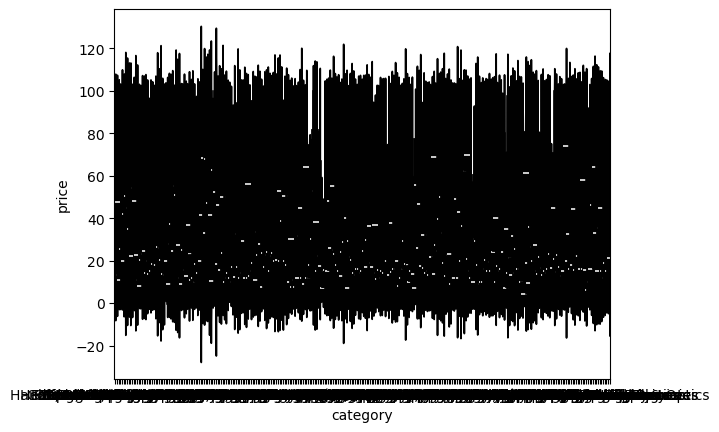

In [35]:
sns.violinplot(data=filtered_data, x="category", y="price", palette="magma", hue="category")
plt.show()

Having all product categories in a single visualisation does not yield readable results.

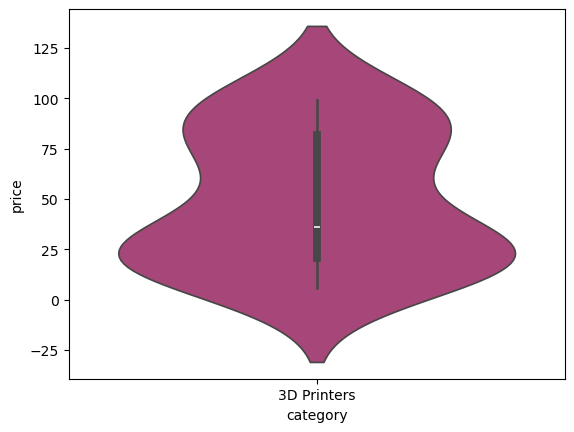

In [ ]:
sns.violinplot(data=filtered_data, x="category", y="price", palette="magma", hue="category")
plt.show()
